# Supplementary Figure S11b. Colocalization at the GDA locus

ColocBoost colocalization at the chr9 GDA locus for the excitatory-neuron *GDA* cis-eQTL, the astrocyte *trans*-eProgram 80 QTL and 11 *trans*-glycosylation QTLs (nine glycoproteins). The y-axis is $-\log_{10}(p)$ of the marginal association, with $p = 2\Phi(-|z|)$ from the stored z-scores (as in `colocboost_plot`), for variants 2000-4000 of the region (chr9:71.66-72.79 Mb). Orange points are the variants of the 95% colocalization confidence set (CoS2, five variants, top variant chr9:72219468:C:T) reported by ColocBoost after `get_robust_colocalization(pvalue_cutoff = 1e-5)`; this CoS colocalizes exactly these 13 traits.

Note: the source notebook replaced CoS2 with the 20 variants of largest |z| for the GDA cis-eQTL before plotting (only 4 of them are in the real set). This notebook plots the real ColocBoost set; the author's set is kept in column `in_author_override_set` and in `cos_comparison` for reference only.

Input: `data/Figure_S11b_GDA_locus.rds`


In [1]:
library(ggplot2)
library(patchwork)
dat <- readRDS("data/Figure_S11b_GDA_locus.rds")
dat$cos_summary
dat$cos_comparison
head(dat$locus)
table(dat$locus$trait[dat$locus$in_colocalized_set])

,cos_id,top_variable,cos_npc,n_variants
,<chr>,<chr>,<dbl>,<int>
cos1:y18_y35,cos1,chr9:72197772:C:T,0.6697,10
cos2:y1_y3_y4_y5_y7_y9_y10_y12_y14_y15_y16_y17_y33,cos2,chr9:72219468:C:T,0.9999,5
cos3:y13_y19_y20_y21_y22_y23_y24_y26_y27_y28_y29_y34,cos3,chr9:72186832:C:T,0.9994,3


variant_index,variant,z_Exc_GDA,in_real_CoS2,in_author_override,vcp
<int>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>
2942,chr9:72219468:C:T,6.644831,TRUE,FALSE,5.161160e-01
2947,chr9:72221869:T:A,7.062586,TRUE,TRUE,4.069914e-01
2957,chr9:72229254:G:A,6.744115,FALSE,TRUE,8.118063e-03
2959,chr9:72231073:C:A,6.921640,FALSE,TRUE,8.132829e-03
2960,chr9:72231188:A:G,6.939859,FALSE,TRUE,9.063541e-03
2968,chr9:72236016:A:C,6.982821,TRUE,TRUE,9.377994e-03
2970,chr9:72236595:A:T,7.030260,FALSE,TRUE,9.273506e-03
2971,chr9:72236622:C:G,6.982821,TRUE,TRUE,9.377994e-03
2973,chr9:72236972:G:A,6.982821,TRUE,TRUE,9.377994e-03


,trait,variant_index,variant,position_bp,z,neg_log10_p,in_colocalized_set,in_author_override_set
,<fct>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<lgl>,<lgl>
1,Excitatory neuron GDA cis-eQTL,2000,chr9:71663292:C:A,71663292,-0.8545746,0.4058432,FALSE,FALSE
2,Excitatory neuron GDA cis-eQTL,2001,chr9:71663335:G:T,71663335,-0.7415532,0.3387951,FALSE,FALSE
3,Excitatory neuron GDA cis-eQTL,2002,chr9:71663564:T:C,71663564,1.0745293,0.5488501,FALSE,FALSE
4,Excitatory neuron GDA cis-eQTL,2003,chr9:71664397:A:G,71664397,-1.8095540,1.1526434,FALSE,FALSE
5,Excitatory neuron GDA cis-eQTL,2004,chr9:71664455:C:G,71664455,-1.6391353,0.9948835,FALSE,FALSE
6,Excitatory neuron GDA cis-eQTL,2005,chr9:71664501:A:G,71664501,-1.4867663,0.8630368,FALSE,FALSE



           Excitatory neuron GDA cis-eQTL 
                                        5 
Astrocyte trans-eProgram QTL (Program 80) 
                                        5 
  NRCAM trans-glycosylation QTL (gp_7423) 
                                        5 
  NRCAM trans-glycosylation QTL (gp_7553) 
                                        5 
          CNTNAP1 trans-glycosylation QTL 
                                        5 
           ADAM10 trans-glycosylation QTL 
                                        5 
  NFASC trans-glycosylation QTL (gp_0587) 
                                        5 
  NFASC trans-glycosylation QTL (gp_0666) 
                                        5 
           COL6A3 trans-glycosylation QTL 
                                        5 
            PRELP trans-glycosylation QTL 
                                        5 
            CNTN2 trans-glycosylation QTL 
                                        5 
             ASPH trans-glycosylation QTL 
          

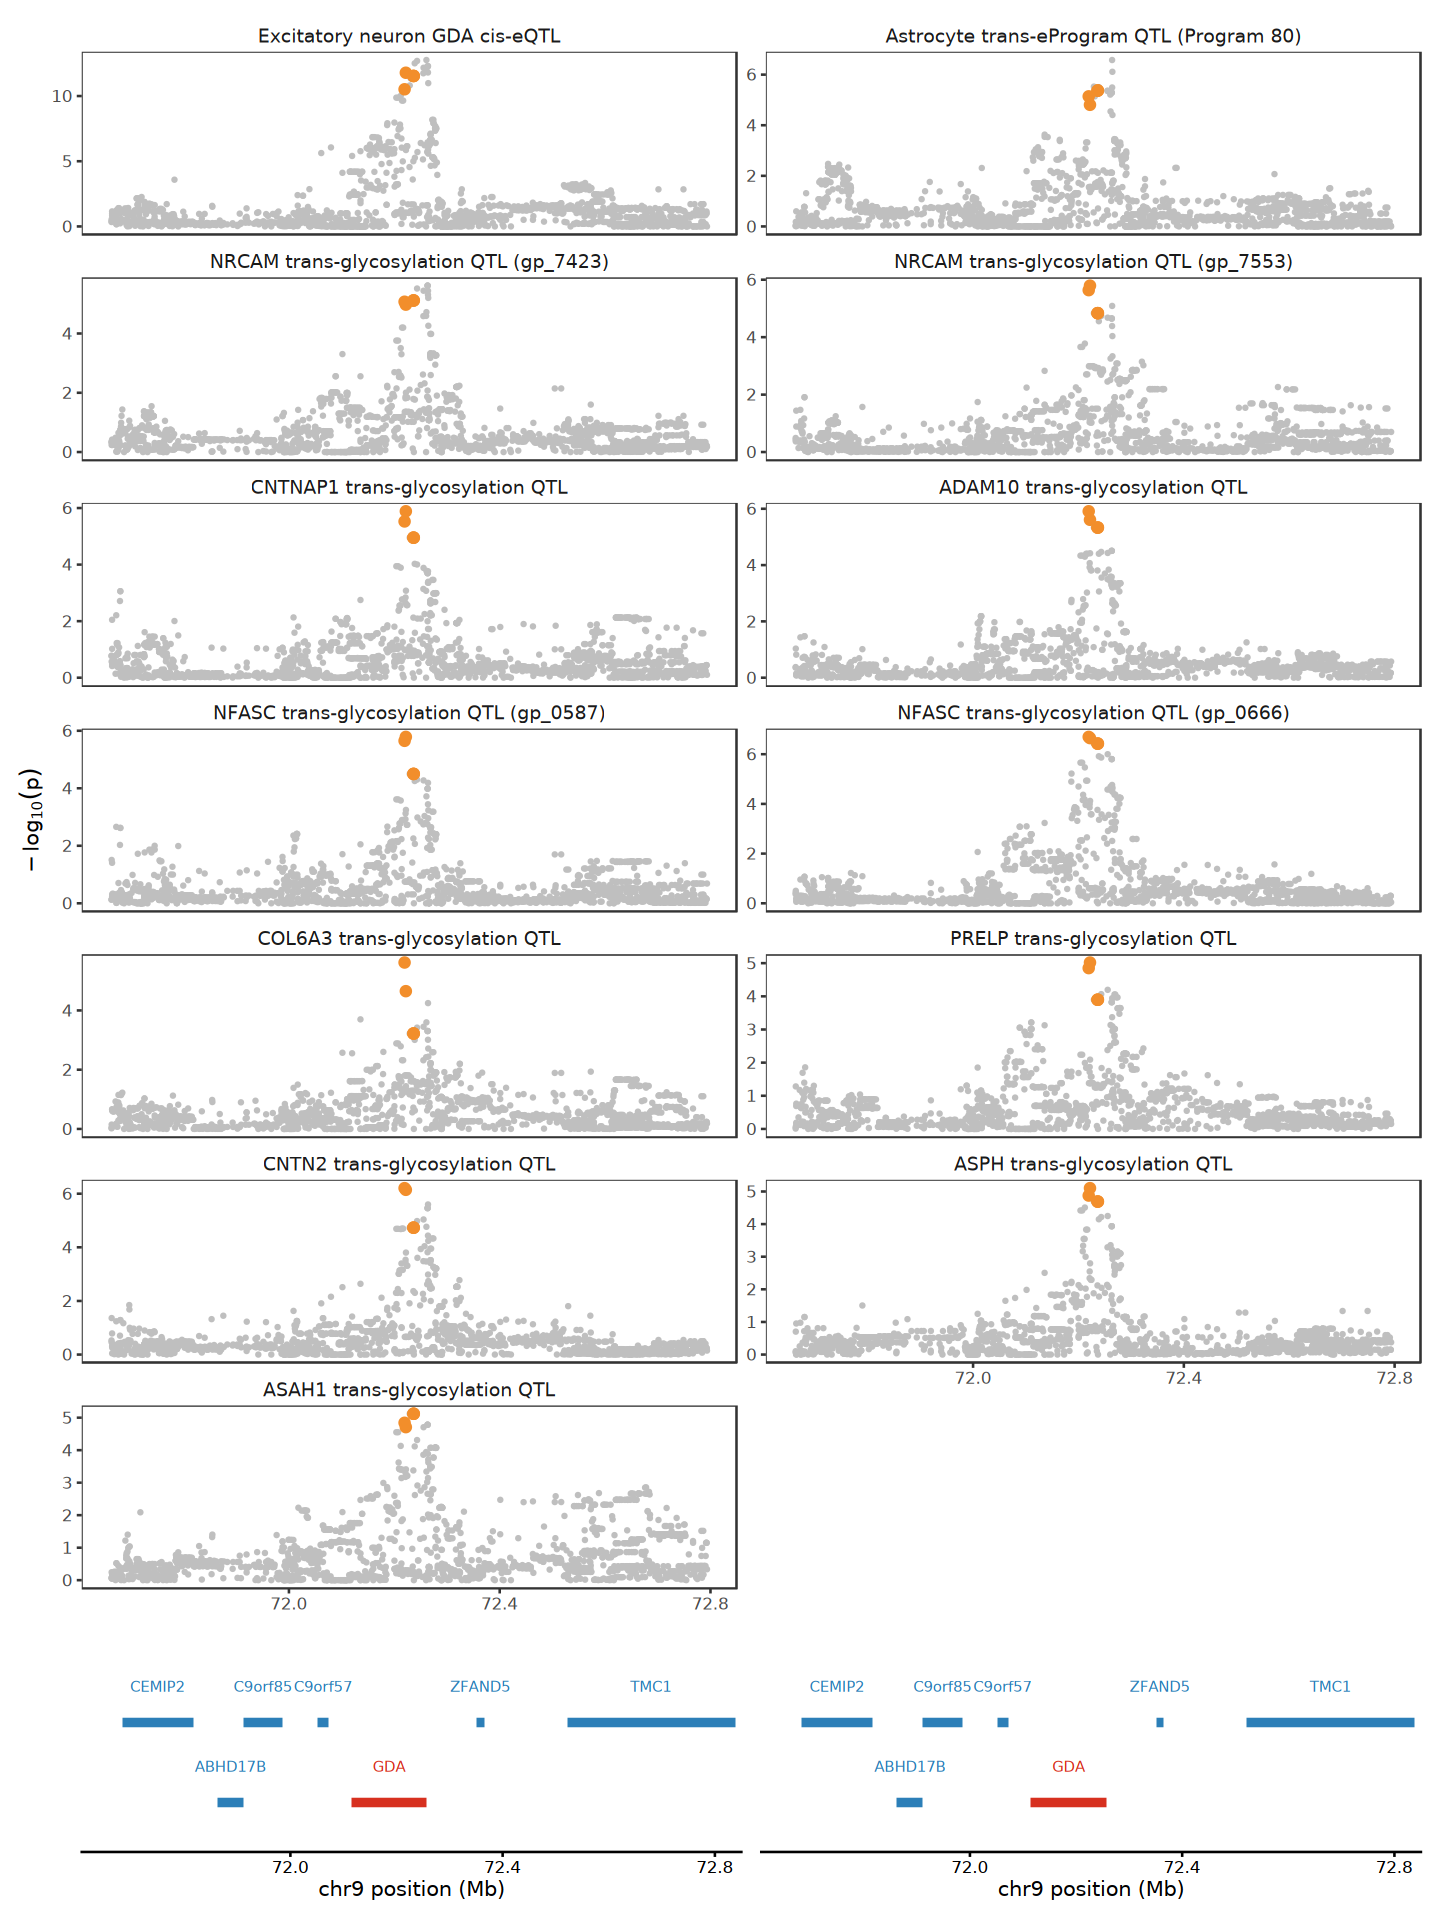

In [2]:
loc <- dat$locus
xlim <- range(loc$position_bp) / 1e6
p_loc <- ggplot(loc, aes(position_bp / 1e6, neg_log10_p)) +
  geom_point(data = loc[!loc$in_colocalized_set, ], colour = "grey75", size = 0.7) +
  geom_point(data = loc[loc$in_colocalized_set, ], colour = "#F28E2B", size = 2.4) +
  facet_wrap(~trait, ncol = 2, scales = "free_y") +
  coord_cartesian(xlim = xlim) +
  labs(x = NULL, y = expression(-log[10](p))) +
  theme_bw(base_size = 12) +
  theme(panel.grid = element_blank(), strip.background = element_blank(),
        strip.text = element_text(size = 11))

genes <- dat$genes[order(dat$genes$start), ]
row_end <- numeric(0); genes$row <- NA
for (i in seq_len(nrow(genes))) {
  r <- which(row_end < genes$start[i] - 0.06e6)[1]
  if (is.na(r)) r <- length(row_end) + 1
  row_end[r] <- genes$end[i]; genes$row[i] <- r
}
p_gene <- ggplot(genes) +
  geom_segment(aes(x = start / 1e6, xend = end / 1e6, y = -row, yend = -row, colour = highlight), linewidth = 2) +
  geom_text(aes(x = (start + end) / 2e6, y = -row + 0.45, label = gene, colour = highlight),
            size = 3, fontface = "italic") +
  scale_colour_manual(values = c(`TRUE` = "#D7301F", `FALSE` = "#2C7FB8"), guide = "none") +
  coord_cartesian(xlim = xlim) +
  scale_y_continuous(limits = c(-max(genes$row) - 0.5, 0)) +
  labs(x = "chr9 position (Mb)", y = NULL) +
  theme_classic(base_size = 12) +
  theme(axis.text.y = element_blank(), axis.ticks.y = element_blank(), axis.line.y = element_blank())

p_gene_r <- p_gene + labs(x = "chr9 position (Mb)")
p <- p_loc / (p_gene | p_gene_r) + plot_layout(heights = c(7, 1))
options(repr.plot.width = 12, repr.plot.height = 16)
p